<a href="https://colab.research.google.com/github/selomuo/selahattin/blob/main/Kestirimci_Bakim_Projesi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# CSV dosyamızı okuyoruz
df = pd.read_csv('ai4i2020.csv')

# Veri setinin ilk 5 satırını ekrana yazdırıyoruz
df.head()

# Veri setinin genel özetini ve boş değer olup olmadığını kontrol ediyoruz
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [3]:
# Kullanmayacağımız gereksiz kimlik sütunlarını siliyoruz
df_clean = df.drop(columns=['UDI', 'Product ID'])

# 'Type' sütunundaki L, M ve H kategorilerini sayılara dönüştürüyoruz (L: 0, M: 1, H: 2)
df_clean['Type'] = df_clean['Type'].map({'L': 0, 'M': 1, 'H': 2})

# Yeni veri setimizin ilk 3 satırına bakalım
df_clean.head(3)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,0,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,0,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


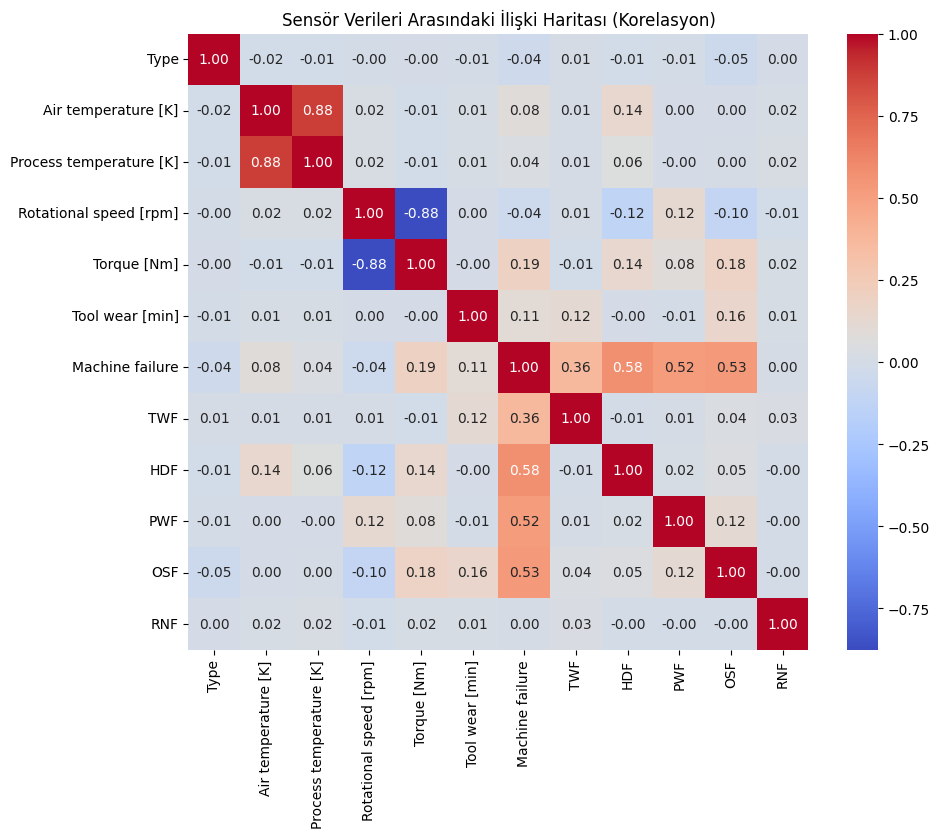

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik boyutunu ayarlıyoruz
plt.figure(figsize=(10, 8))

# Veriler arasındaki korelasyonu hesaplayıp ısı haritası (heatmap) olarak çizdiriyoruz
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Sensör Verileri Arasındaki İlişki Haritası (Korelasyon)')
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Girdileri (Sensörler) ve Hedefi (Arıza Durumu) belirliyoruz
# Makine arızasını doğrudan etkileyen sensör verilerini X'e alıyoruz
X = df_clean[['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']]
y = df_clean['Machine failure']  # Tahmin etmek istediğimiz hedef

# 2. Veriyi %80 Eğitim, %20 Test olarak ikiye bölüyoruz
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Random Forest Yapay Zeka Modelimizi oluşturuyoruz
model = RandomForestClassifier(random_state=42)

# 4. Modeli eğitiyoruz (Yapay zeka burada kalıpları öğreniyor)
model.fit(X_train, y_train)

# 5. Test verileriyle tahmin yapıyoruz
y_pred = model.predict(X_test)

# 6. Sonuçları ekrana yazdırıyoruz
print("Yapay Zeka Doğruluk Skoru (Accuracy):", accuracy_score(y_test, y_pred))
print("\nDetaylı Başarı Raporu:\n", classification_report(y_test, y_pred))

Yapay Zeka Doğruluk Skoru (Accuracy): 0.9845

Detaylı Başarı Raporu:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      1939
           1       0.86      0.59      0.70        61

    accuracy                           0.98      2000
   macro avg       0.92      0.79      0.85      2000
weighted avg       0.98      0.98      0.98      2000



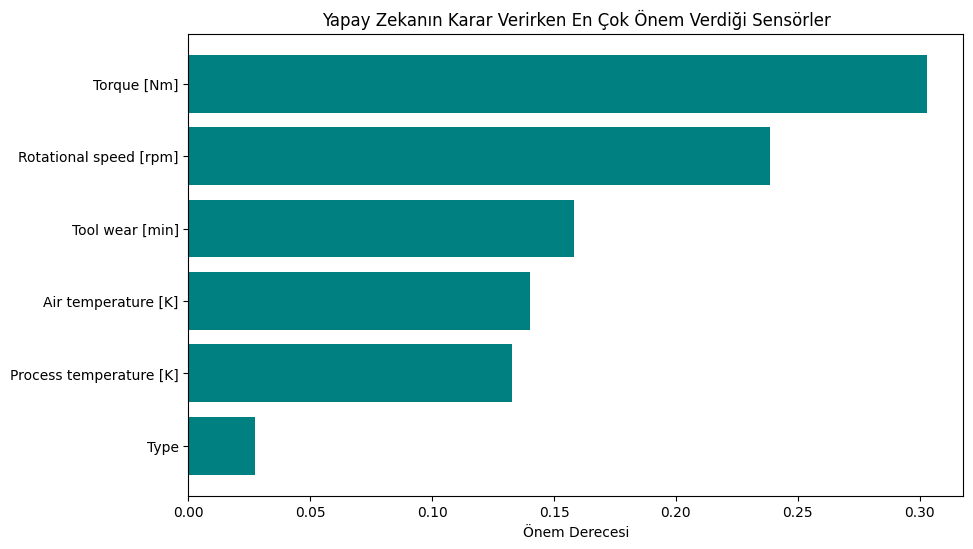

In [6]:
import numpy as np

# Sensörlerin önem derecelerini alıyoruz
importances = model.feature_importances_
features = X.columns

# Görselleştirmek için sıralıyoruz
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Yapay Zekanın Karar Verirken En Çok Önem Verdiği Sensörler')
plt.barh(range(len(indices)), importances[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Önem Derecesi')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')